# Phase 5 - RUL Prediction with Random Forest and XGBoost

**Objective.** Run Experiment 1 (Random Forest vs XGBoost) and Experiment 3 (raw sensors vs summary statistics, including the normalisation comparison on FD002).

**Why this is needed.** These experiments provide the evidence for the prognostic part of RQ1 and for RQ2.

**Procedure, identical for both models and all data configurations.**

1. *Engine-level cross-validation.* Training engines are split into 5 folds by engine number, so all cycles of an engine stay together. Preprocessing is refitted on the training folds each time.
2. *Hyperparameter choice.* Each model has 6 candidate settings. The one with the lowest mean cross-validated RMSE is selected.
3. *Final fit* on all training engines.
4. *Test.* One prediction per official test engine at its last observed cycle. The test engines are used once, after every choice has been made.

**Metrics.** MAE is the average error in cycles. RMSE is also in cycles but weights large errors more. $R^2$ is the share of the variation in true RUL that the predictions explain.

Code: `src/rul_prediction.py` (training) and `src/evaluation.py` (metrics, intervals, figures).

In [1]:
import sys
sys.path.insert(0, '..')

import json
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl
from src import evaluation as ev
from src import rul_prediction as rp

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.precision', 3)

# Training takes about 16 minutes, so saved results are reused when the settings are unchanged.
# To retrain everything: rp.run_all(force=True)
paths = rp.run_all()
saved = ev.save_rul_figures()
config = json.loads(paths['phase5_experiment_config'].read_text())
print('Training time of the saved run:', config['total_minutes'], 'minutes')

Saved Phase 5 results match the current settings; nothing was retrained.


Training time of the saved run: 16.2 minutes


## 1. Model settings

Fixed settings and the tuned grid for each model.

In [2]:
for model in rp.MODELS:
    print(rp.MODEL_LABELS[model])
    print('  fixed :', rp.FIXED_PARAMS[model])
    print('  tuned :', rp.PARAM_GRIDS[model], '->', len(rp.candidates(model)), 'candidates')

Random Forest
  fixed : {'n_estimators': 200, 'n_jobs': -1, 'random_state': 42}
  tuned : {'max_features': ['sqrt', 0.33], 'min_samples_leaf': [5, 20, 50]} -> 6 candidates
XGBoost
  fixed : {'n_estimators': 300, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'objective': 'reg:squarederror', 'n_jobs': -1, 'random_state': 42}
  tuned : {'max_depth': [3, 5, 7], 'learning_rate': [0.05, 0.1]} -> 6 candidates


## 2. Cross-validation results

Mean and standard deviation over the 5 folds for the selected candidate of every configuration.

In [3]:
cv = pd.read_csv(paths['phase5_cv_summary'])
selected = cv[cv['selected']].drop(columns='selected')
selected[['subset', 'scheme', 'representation', 'model', 'params',
          'cv_rmse_mean', 'cv_rmse_std', 'cv_mae_mean', 'cv_r2_mean']]

,subset,scheme,representation,model,params,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean
0,FD001,global,raw,random_forest,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",18.536,0.728,13.646,0.802
6,FD001,global,raw,xgboost,"{""max_depth"": 3, ""learning_rate"": 0.05}",18.650,0.674,13.548,0.799
12,FD001,global,summary,random_forest,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",17.318,0.600,12.809,0.827
20,FD001,global,summary,xgboost,"{""max_depth"": 5, ""learning_rate"": 0.05}",17.106,0.900,12.400,0.831
24,FD002,global,raw,random_forest,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",19.525,0.716,14.681,0.780
34,FD002,global,raw,xgboost,"{""max_depth"": 7, ""learning_rate"": 0.05}",19.695,0.778,14.485,0.776
39,FD002,global,summary,random_forest,"{""max_features"": 0.33, ""min_samples_leaf"": 5}",19.674,0.607,15.010,0.777
46,FD002,global,summary,xgboost,"{""max_depth"": 7, ""learning_rate"": 0.05}",19.585,0.654,14.522,0.779
48,FD002,condition,raw,random_forest,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",19.627,0.694,14.674,0.778
56,FD002,condition,raw,xgboost,"{""max_depth"": 5, ""learning_rate"": 0.05}",19.625,0.750,14.433,0.778


In [4]:
# How much did tuning matter? Spread of mean CV RMSE across the 6 candidates of each configuration
spread = cv.groupby(['subset', 'scheme', 'representation', 'model'], sort=False)['cv_rmse_mean'].agg(['min', 'max'])
spread['range'] = spread['max'] - spread['min']
spread

min     max  range
subset scheme    representation model                               
FD001  global    raw            random_forest  18.536  18.840  0.304
                                xgboost        18.650  19.255  0.604
                 summary        random_forest  17.318  17.928  0.610
                                xgboost        17.106  17.563  0.457
FD002  global    raw            random_forest  19.525  19.949  0.424
                                xgboost        19.695  20.424  0.729
                 summary        random_forest  19.674  20.777  1.103
                                xgboost        19.585  20.509  0.924
       condition raw            random_forest  19.627  19.820  0.193
                                xgboost        19.625  19.941  0.317
                 summary        random_forest  19.344  19.527  0.183
                                xgboost        19.043  19.739  0.695

**Reading the tables.** Cross-validated RMSE lies between about 17 and 20 cycles in every configuration. The gap between the best and worst candidate is 0.2 to 1.1 cycles, similar in size to the fold-to-fold standard deviation (0.6 to 1.0), so the models are not very sensitive to the tuned settings within this grid.

Cross-validation scores cover *all cycles* of the validation engines. Test scores below use *one cycle per engine*. The two are therefore not directly comparable.

## 3. Test results

Main result: target capped at 125. The uncapped columns compare the same predictions with the original NASA values.

In [5]:
ev.rul_results_table().drop(columns='params')

,data,representation,model,n_features,cv_rmse,test_mae,test_rmse,test_rmse_95ci,test_r2,test_mae_uncapped,test_rmse_uncapped,test_r2_uncapped
0,FD001,Raw sensors,Random Forest,15,18.54 +/- 0.73,11.828,16.856,13.68 to 19.82,0.823,12.898,17.864,0.815
1,FD001,Raw sensors,XGBoost,15,18.65 +/- 0.67,11.764,16.991,13.72 to 20.11,0.820,12.834,17.955,0.813
2,FD001,Summary statistics,Random Forest,45,17.32 +/- 0.60,11.907,16.409,13.48 to 19.35,0.832,12.977,17.535,0.822
3,FD001,Summary statistics,XGBoost,45,17.11 +/- 0.90,11.593,15.829,13.03 to 18.66,0.844,12.663,17.096,0.831
4,"FD002, dataset-wide normalisation",Raw sensors,Random Forest,21,19.53 +/- 0.72,12.946,17.008,15.27 to 18.71,0.843,20.440,29.157,0.706
5,"FD002, dataset-wide normalisation",Raw sensors,XGBoost,21,19.70 +/- 0.78,12.972,17.185,15.38 to 19.01,0.840,20.466,29.062,0.708
6,"FD002, dataset-wide normalisation",Summary statistics,Random Forest,63,19.67 +/- 0.61,13.263,17.396,15.66 to 19.14,0.836,20.757,29.675,0.696
7,"FD002, dataset-wide normalisation",Summary statistics,XGBoost,63,19.58 +/- 0.65,13.090,16.918,15.34 to 18.57,0.845,20.549,28.994,0.709
8,"FD002, per-condition normalisation",Raw sensors,Random Forest,17,19.63 +/- 0.69,13.003,17.536,15.55 to 19.62,0.833,20.497,29.503,0.699
9,"FD002, per-condition normalisation",Raw sensors,XGBoost,17,19.62 +/- 0.75,13.224,17.734,15.81 to 19.80,0.829,20.711,29.568,0.698


**Reading the table.**

- With the capped target, test RMSE is between 15.8 and 17.7 cycles and $R^2$ between 0.82 and 0.86 in all twelve configurations.
- The 95% intervals are several cycles wide, wider than most differences between configurations.
- Against the uncapped NASA values FD001 changes by about one cycle, but FD002 rises to about 29 cycles. 57 of the 259 FD002 test engines have a true RUL above 125 (11 of 100 in FD001), and a model trained on a target capped at 125 cannot predict more than about 125. Results from other studies must be compared with the column that matches their evaluation convention.

## 4. Figure 4 - Actual vs predicted RUL

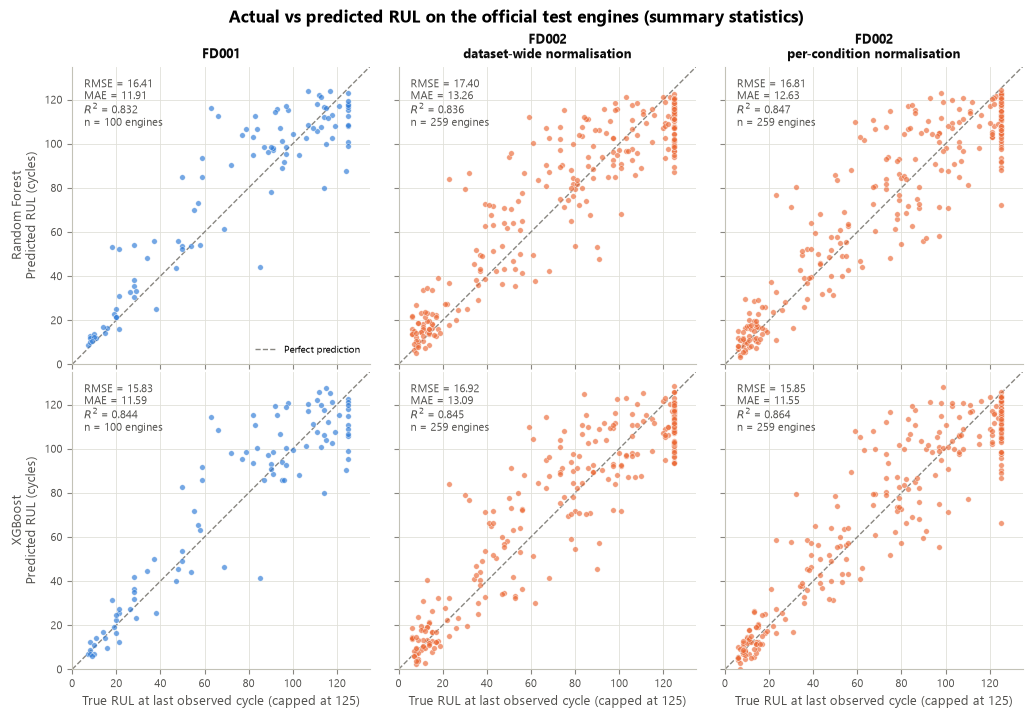

In [6]:
fig = ev.plot_actual_vs_predicted('summary')
plt.show()

**Reading the figure.** Each point is one test engine; the dashed line is a perfect prediction. Predictions are tight for engines close to failure and spread out for engines with more life left. The column of points at 125 contains the engines whose true RUL is 125 or more.

## 5. Experiment 1 - Random Forest vs XGBoost (Figure 5)

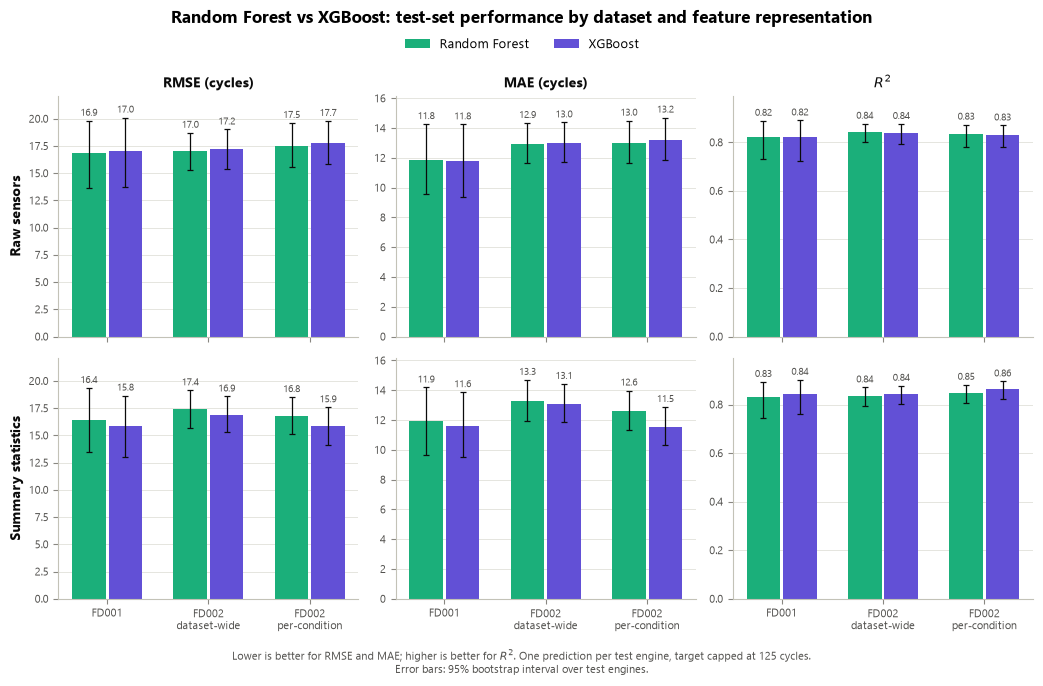

In [7]:
fig = ev.plot_model_comparison()
plt.show()

In [8]:
diffs = ev.paired_rmse_differences()
diffs[diffs['comparison'] == 'model'].drop(columns='comparison').round(2)

,context,A,B,rmse_A,rmse_B,difference_B_minus_A,ci_low,ci_high,interval_excludes_zero
0,FD001; raw sensors,Random Forest,XGBoost,16.86,16.99,0.13,-0.57,0.79,False
1,FD001; summary statistics,Random Forest,XGBoost,16.41,15.83,-0.58,-1.86,0.61,False
2,"FD002, dataset-wide normalisation; raw sensors",Random Forest,XGBoost,17.01,17.18,0.18,-0.23,0.58,False
3,"FD002, dataset-wide normalisation; summary statistics",Random Forest,XGBoost,17.40,16.92,-0.48,-1.14,0.21,False
4,"FD002, per-condition normalisation; raw sensors",Random Forest,XGBoost,17.54,17.73,0.20,-0.22,0.67,False
5,"FD002, per-condition normalisation; summary statistics",Random Forest,XGBoost,16.81,15.85,-0.96,-1.69,-0.31,True


**Reading the figure and table.** `difference_B_minus_A` is XGBoost RMSE minus Random Forest RMSE on the same test engines; negative means XGBoost is better. With raw sensors the two models are within 0.2 cycles of each other on every dataset. With summary statistics XGBoost is lower by 0.5 to 1.0 cycles. Only one of the six intervals excludes zero (FD002, per-condition normalisation, summary statistics).

## 6. Experiment 3 - Raw sensors vs summary statistics (Figure 7)

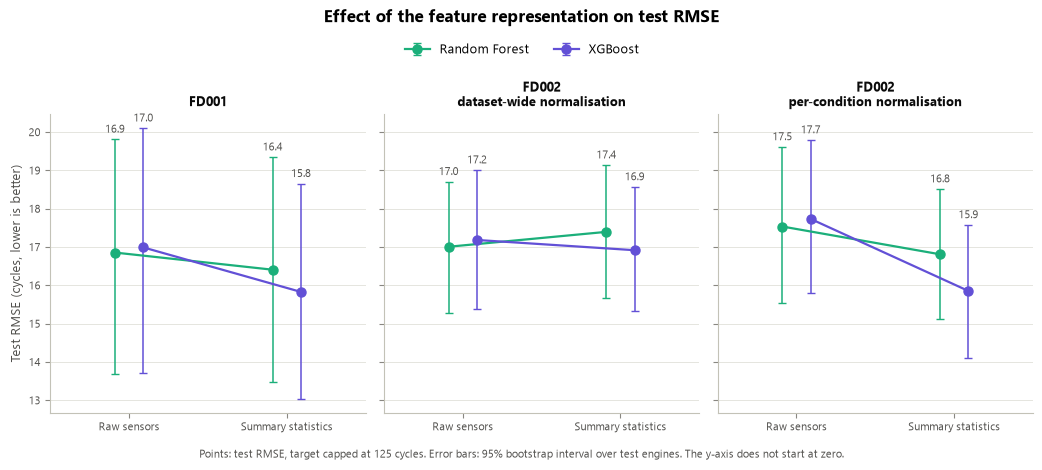

In [9]:
fig = ev.plot_representation_comparison()
plt.show()

In [10]:
diffs[diffs['comparison'] == 'representation'].drop(columns='comparison').round(2)

,context,A,B,rmse_A,rmse_B,difference_B_minus_A,ci_low,ci_high,interval_excludes_zero
6,FD001; Random Forest,Raw sensors,Summary statistics,16.86,16.41,-0.45,-1.82,1.10,False
7,FD001; XGBoost,Raw sensors,Summary statistics,16.99,15.83,-1.16,-3.67,1.32,False
8,"FD002, dataset-wide normalisation; Random Forest",Raw sensors,Summary statistics,17.01,17.40,0.39,-0.11,0.91,False
9,"FD002, dataset-wide normalisation; XGBoost",Raw sensors,Summary statistics,17.18,16.92,-0.27,-0.91,0.40,False
10,"FD002, per-condition normalisation; Random Forest",Raw sensors,Summary statistics,17.54,16.81,-0.73,-1.91,0.42,False
11,"FD002, per-condition normalisation; XGBoost",Raw sensors,Summary statistics,17.73,15.85,-1.88,-3.43,-0.40,True


**Reading the figure and table.** Negative values mean summary statistics are better. Summary statistics lower the test RMSE in five of six cases, by 0.3 to 1.9 cycles, and raise it in one (Random Forest on FD002 with dataset-wide normalisation). Only one interval excludes zero (XGBoost on FD002 with per-condition normalisation).

## 7. Normalisation scheme on FD002

In [11]:
diffs[diffs['comparison'] == 'normalisation'].drop(columns='comparison').round(2)

,context,A,B,rmse_A,rmse_B,difference_B_minus_A,ci_low,ci_high,interval_excludes_zero
12,FD002; raw sensors; Random Forest,Dataset-wide,Per-condition,17.01,17.54,0.53,-0.06,1.16,False
13,FD002; raw sensors; XGBoost,Dataset-wide,Per-condition,17.18,17.73,0.55,-0.05,1.16,False
14,FD002; summary statistics; Random Forest,Dataset-wide,Per-condition,17.40,16.81,-0.59,-1.60,0.44,False
15,FD002; summary statistics; XGBoost,Dataset-wide,Per-condition,16.92,15.85,-1.06,-2.44,0.39,False


**Reading the table.** Negative values mean per-condition normalisation is better. With raw sensors per-condition normalisation is about 0.5 cycles *worse* for both models. With summary statistics it is 0.6 to 1.1 cycles better. All four intervals include zero.

This differs from the correlation analysis in Phases 2 to 4, where per-condition normalisation made individual sensors far more informative. Tree models can separate the operating conditions themselves, because under dataset-wide normalisation sensors such as s1 and s5 still show which condition a row belongs to. The benefit of per-condition normalisation appears only when readings from different conditions are averaged together in the window statistics.

## 8. Summary of evidence

1. **Accuracy (RQ1, prognostic part).** Both models predict the capped RUL of test engines with an RMSE of about 16 to 18 cycles on FD001 and on FD002.
2. **Model comparison.** Random Forest and XGBoost perform alike. XGBoost has a small advantage with summary statistics.
3. **Feature representation (RQ2).** Summary statistics usually help a little. The gain is clearest for XGBoost on FD002 with per-condition normalisation.
4. **Normalisation (RQ2).** Per-condition normalisation does not help tree models on raw readings and helps somewhat when combined with summary statistics.
5. **Strength of evidence.** Sixteen paired comparisons were made and two intervals exclude zero. With this many comparisons one such result could arise by chance; no correction was applied. Most differences are too small to be distinguished with 100 or 259 test engines.

Results are from simulated data, a single random seed and one train/test split.